# Plot Formatting and Data Analysis (Univariate, Bivariate, Multivariate)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

print("NumPy version     :", np.__version__)
print("Pandas version    :", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

NumPy version     : 2.5.3
Pandas version    : 3.0.5
Matplotlib version: 3.11.2


In [2]:
# Build the dataset (random seed fixed so everyone gets the same numbers)
rng = np.random.default_rng(42)
n = 500

area      = np.clip(rng.lognormal(mean=7.2, sigma=0.35, size=n), 450, 4000).round()   # right-skewed
bedrooms  = np.clip((area / 550 + rng.normal(0, 0.5, n)).round(), 1, 5).astype(int)   # grows with area
age       = rng.integers(0, 31, n)                                                    # 0-30 years
distance  = np.clip(rng.exponential(8, n) + 1, 1, 40).round(1)                        # km from city centre
zone      = np.where(distance < 6, "Central", np.where(distance < 14, "Suburb", "Outskirts"))

# The "hidden rule" that creates price (+ random noise, like real life)
price = 15 + 0.04 * area - 0.6 * age - 1.2 * distance + 3 * bedrooms + rng.normal(0, 8, n)
luxury = rng.choice(n, 8, replace=False)      # a few very expensive houses = outliers
price[luxury] += 70
price = np.clip(price, 10, None).round(1)

df = pd.DataFrame({
    "area_sqft": area, "bedrooms": bedrooms, "age_years": age,
    "distance_km": distance, "zone": zone, "price_lakhs": price,
})
df.head()

,area_sqft,bedrooms,age_years,distance_km,zone,price_lakhs
0,1490.0,3,5,10.7,Suburb,58.4
1,931.0,2,20,5.4,Central,103.5
2,1742.0,3,12,3.4,Central,77.4
3,1862.0,3,10,12.2,Suburb,69.4
4,677.0,1,21,6.8,Suburb,15.9


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (500, 6)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   area_sqft    500 non-null    float64
 1   bedrooms     500 non-null    int64  
 2   age_years    500 non-null    int64  
 3   distance_km  500 non-null    float64
 4   zone         500 non-null    str    
 5   price_lakhs  500 non-null    float64
dtypes: float64(3), int64(2), str(1)
memory usage: 23.6 KB


In [4]:
#check: missing values and basic statistics
print("Missing values per column:\n", df.isna().sum(), "\n")
df.describe().round(1)

Missing values per column:
 area_sqft      0
bedrooms       0
age_years      0
distance_km    0
zone           0
price_lakhs    0
dtype: int64 



,area_sqft,bedrooms,age_years,distance_km,price_lakhs
count,500.0,500.0,500.0,500.0,500.0
mean,1411.4,2.5,14.6,9.5,59.3
std,495.2,1.0,8.9,8.2,26.1
min,545.0,1.0,0.0,1.0,10.0
25%,1060.5,2.0,7.0,3.7,41.0
50%,1340.5,3.0,14.0,6.9,56.4
75%,1644.8,3.0,23.0,12.5,74.1
max,3714.0,5.0,30.0,40.0,165.9


#  Plot Formatting: Markers, Labels, Legends, Grids and Limits

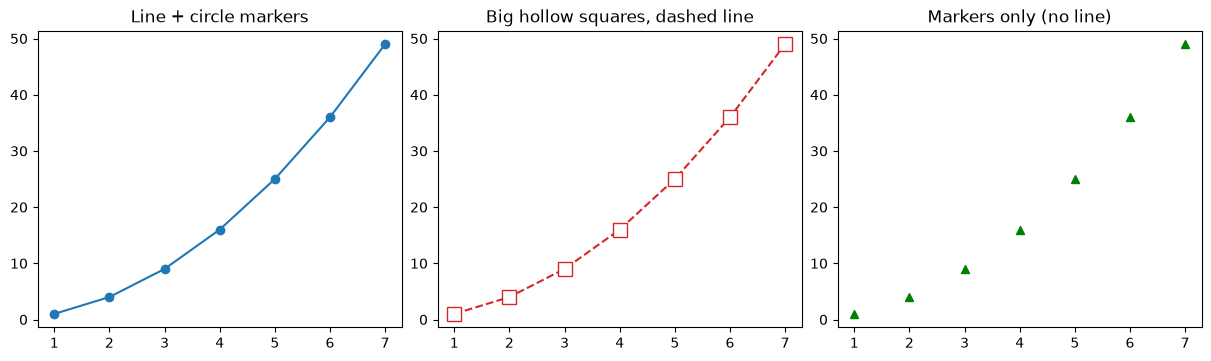

In [5]:
x = np.arange(1, 8)
y = x ** 2

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)

axes[0].plot(x, y, marker="o")
axes[0].set_title("Line + circle markers")

axes[1].plot(x, y, marker="s", markersize=10, markerfacecolor="white",
             markeredgecolor="tab:red", color="tab:red", linestyle="--")
axes[1].set_title("Big hollow squares, dashed line")

axes[2].plot(x, y, marker="^", color="green", linestyle="")      # linestyle="" -> markers only
axes[2].set_title("Markers only (no line)")

plt.show()


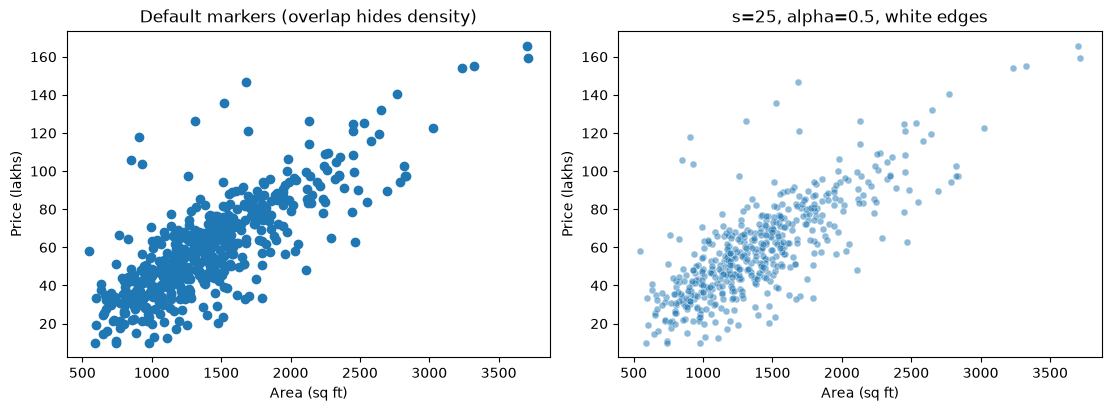

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

axes[0].scatter(df["area_sqft"], df["price_lakhs"])
axes[0].set_title("Default markers (overlap hides density)")

axes[1].scatter(df["area_sqft"], df["price_lakhs"],
                s=25, alpha=0.5, color="tab:blue", edgecolors="white", linewidths=0.5)
axes[1].set_title("s=25, alpha=0.5, white edges")

for ax in axes:
    ax.set_xlabel("Area (sq ft)")
    ax.set_ylabel("Price (lakhs)")
plt.show()


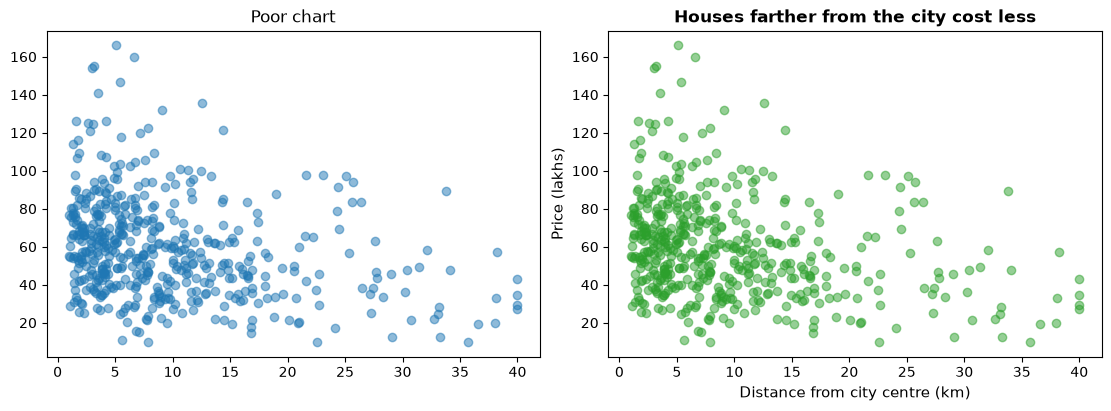

In [7]:
##Labels and Titles
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

# Poor: no labels at all
axes[0].scatter(df["distance_km"], df["price_lakhs"], alpha=0.5)
axes[0].set_title("Poor chart")

# Good: title + labelled axes with units
axes[1].scatter(df["distance_km"], df["price_lakhs"], alpha=0.5, color="tab:green")
axes[1].set_title("Houses farther from the city cost less", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Distance from city centre (km)", fontsize=11)
axes[1].set_ylabel("Price (lakhs)", fontsize=11)

plt.show()


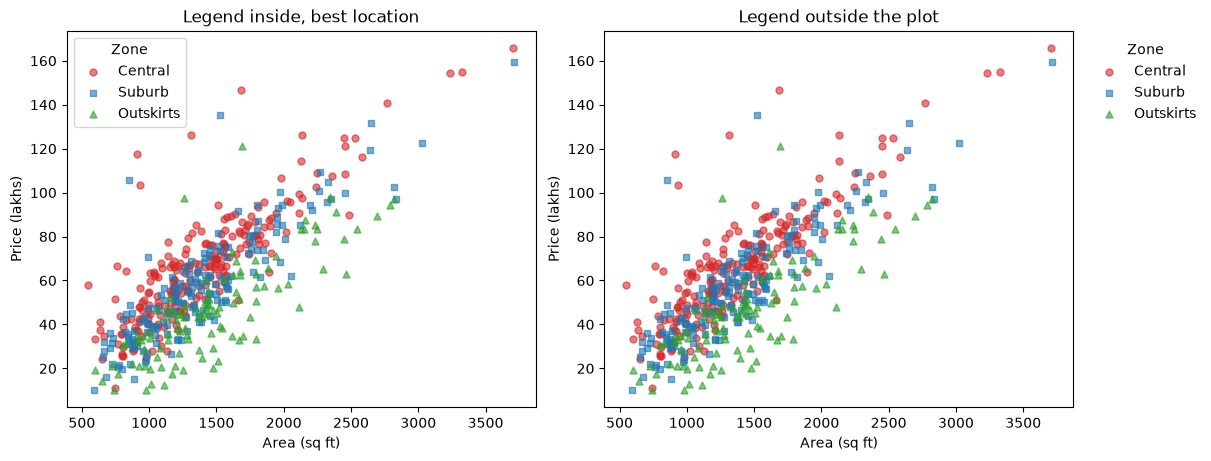

In [8]:
# Legends
colors = {"Central": "tab:red", "Suburb": "tab:blue", "Outskirts": "tab:green"}
markers = {"Central": "o", "Suburb": "s", "Outskirts": "^"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for ax in axes:
    for z in ["Central", "Suburb", "Outskirts"]:
        sub = df[df["zone"] == z]
        ax.scatter(sub["area_sqft"], sub["price_lakhs"], s=25, alpha=0.6,
                   color=colors[z], marker=markers[z], label=z)       # <- label for the legend
    ax.set_xlabel("Area (sq ft)")
    ax.set_ylabel("Price (lakhs)")

axes[0].set_title("Legend inside, best location")
axes[0].legend(title="Zone", loc="best")

axes[1].set_title("Legend outside the plot")
axes[1].legend(title="Zone", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

plt.show()

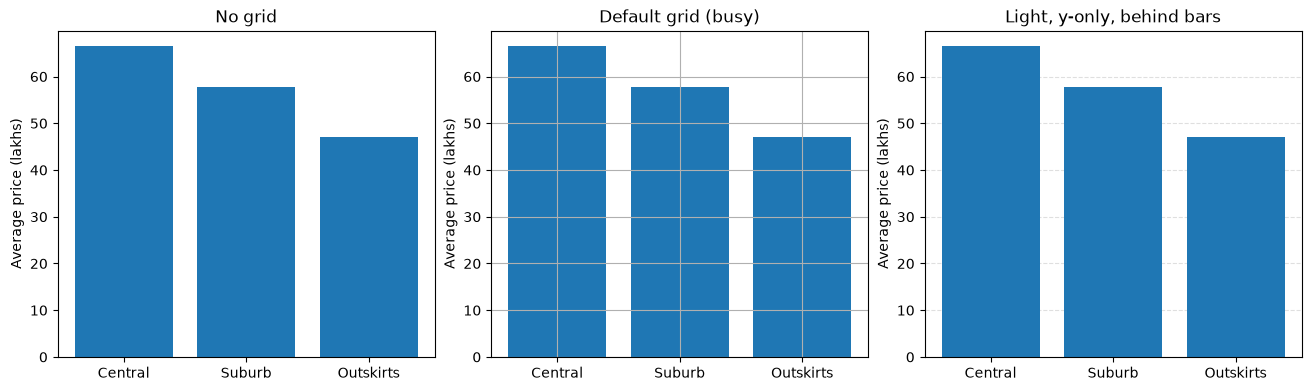

In [9]:
## Grids
mean_price = df.groupby("zone")["price_lakhs"].mean().reindex(["Central", "Suburb", "Outskirts"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)

axes[0].bar(mean_price.index, mean_price.values, color="tab:blue")
axes[0].set_title("No grid")

axes[1].bar(mean_price.index, mean_price.values, color="tab:blue")
axes[1].grid(True)
axes[1].set_title("Default grid (busy)")

axes[2].bar(mean_price.index, mean_price.values, color="tab:blue")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
axes[2].set_axisbelow(True)
axes[2].set_title("Light, y-only, behind bars")

for ax in axes:
    ax.set_ylabel("Average price (lakhs)")
plt.show()


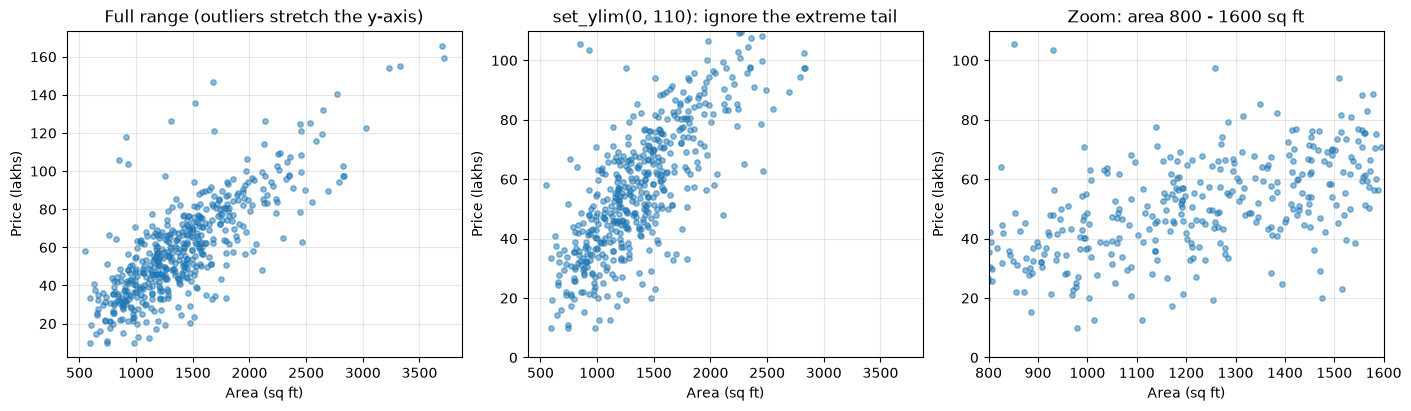

In [10]:
#Limits (axis range)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

axes[0].scatter(df["area_sqft"], df["price_lakhs"], s=15, alpha=0.5)
axes[0].set_title("Full range (outliers stretch the y-axis)")

axes[1].scatter(df["area_sqft"], df["price_lakhs"], s=15, alpha=0.5)
axes[1].set_ylim(0, 110)
axes[1].set_title("set_ylim(0, 110): ignore the extreme tail")

axes[2].scatter(df["area_sqft"], df["price_lakhs"], s=15, alpha=0.5)
axes[2].set_xlim(800, 1600)
axes[2].set_ylim(0, 110)
axes[2].set_title("Zoom: area 800 - 1600 sq ft")

for ax in axes:
    ax.set_xlabel("Area (sq ft)")
    ax.set_ylabel("Price (lakhs)")
    ax.grid(alpha=0.3)
plt.show()


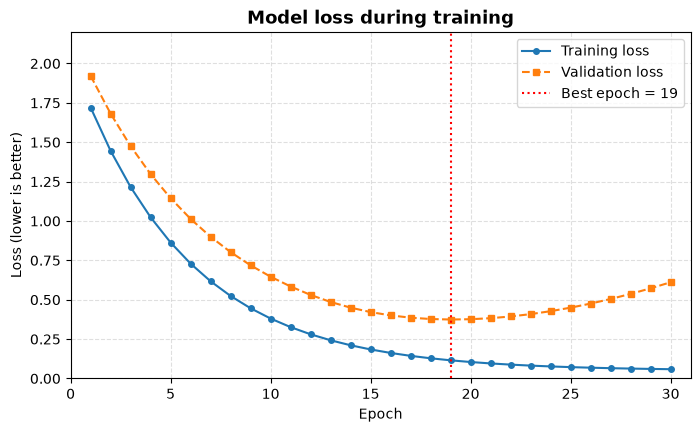

In [11]:
# All five together - a real ML-style chart
epochs = np.arange(1, 31)
train_loss = 2.0 * np.exp(-0.18 * epochs) + 0.05
val_loss   = 2.0 * np.exp(-0.15 * epochs) + 0.20 + 0.0012 * (epochs - 12).clip(min=0) ** 2
best_epoch = epochs[val_loss.argmin()]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(epochs, train_loss, marker="o", markersize=4, color="tab:blue",   label="Training loss")
ax.plot(epochs, val_loss,   marker="s", markersize=4, color="tab:orange", linestyle="--", label="Validation loss")
ax.axvline(best_epoch, color="red", linestyle=":", label=f"Best epoch = {best_epoch}")

ax.set_title("Model loss during training", fontsize=13, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (lower is better)")
ax.set_xlim(0, 31)
ax.set_ylim(0, 2.2)
ax.legend(loc="upper right")
ax.grid(linestyle="--", alpha=0.4)

plt.show()

#  Univariate Analysis - One Variable at a Time


In [12]:
# Numeric variable: centre, spread and shape
price = df["price_lakhs"]

print("Mean   :", round(price.mean(), 1))
print("Median :", round(price.median(), 1))
print("Std dev:", round(price.std(), 1))
print("Min / Max:", price.min(), "/", price.max())
print("Skewness:", round(price.skew(), 2), " (0 = symmetric, > 0 = long right tail)")

Mean   : 59.3
Median : 56.4
Std dev: 26.1
Min / Max: 10.0 / 165.9
Skewness: 0.88  (0 = symmetric, > 0 = long right tail)


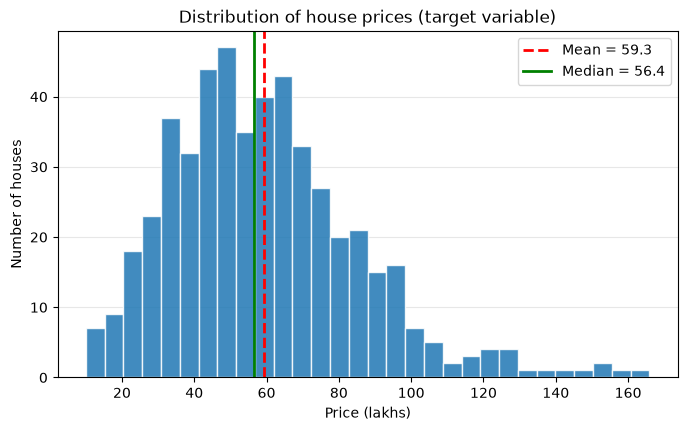

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(price, bins=30, color="tab:blue", edgecolor="white", alpha=0.85)
ax.axvline(price.mean(),   color="red",    linestyle="--", linewidth=2, label=f"Mean = {price.mean():.1f}")
ax.axvline(price.median(), color="green",  linestyle="-",  linewidth=2, label=f"Median = {price.median():.1f}")

ax.set_title("Distribution of house prices (target variable)")
ax.set_xlabel("Price (lakhs)")
ax.set_ylabel("Number of houses")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

Q1 = 41.0, Q3 = 74.1, IQR = 33.1
Outlier fences: below -8.7 or above 123.8
Number of potential outliers: 12


C:\Users\chipp\AppData\Local\Temp\ipykernel_24532\2086446816.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(price, vert=False, patch_artist=True, boxprops=dict(facecolor="lightblue"),


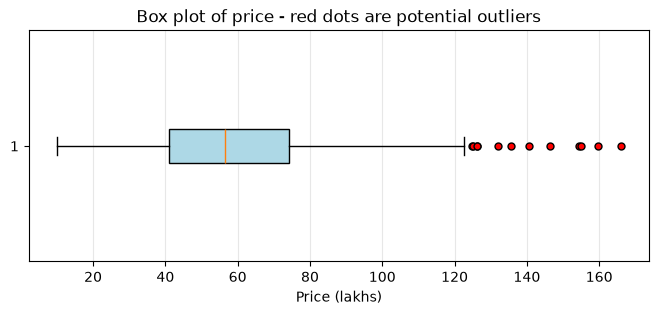

,area_sqft,bedrooms,age_years,distance_km,zone,price_lakhs
248,3703.0,5,26,5.1,Central,165.9
139,3714.0,5,4,6.6,Suburb,159.6
479,3325.0,5,3,3.2,Central,154.9
226,3233.0,5,5,3.0,Central,154.3
39,1682.0,3,8,5.4,Central,146.5


In [14]:
### Box plot and outliers
q1, q3 = price.quantile(0.25), price.quantile(0.75)
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(price < low_fence) | (price > high_fence)]

print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}")
print(f"Outlier fences: below {low_fence:.1f} or above {high_fence:.1f}")
print(f"Number of potential outliers: {len(outliers)}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(price, vert=False, patch_artist=True, boxprops=dict(facecolor="lightblue"),
           flierprops=dict(marker="o", markerfacecolor="red", markersize=5))
ax.set_title("Box plot of price - red dots are potential outliers")
ax.set_xlabel("Price (lakhs)")
ax.grid(axis="x", alpha=0.3)
plt.show()

outliers.sort_values("price_lakhs", ascending=False).head()


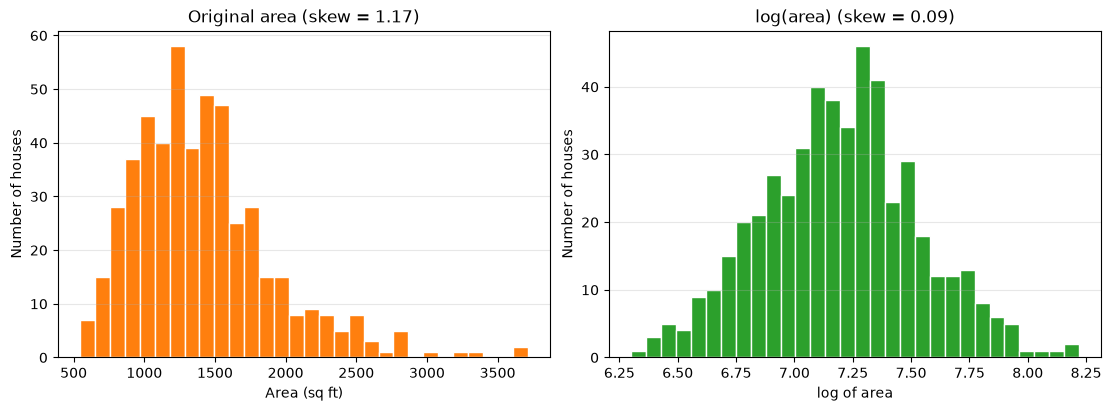

In [15]:
### Fixing skew with a log transform
area_s = df["area_sqft"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

axes[0].hist(area_s, bins=30, color="tab:orange", edgecolor="white")
axes[0].set_title(f"Original area (skew = {area_s.skew():.2f})")
axes[0].set_xlabel("Area (sq ft)")

axes[1].hist(np.log(area_s), bins=30, color="tab:green", edgecolor="white")
axes[1].set_title(f"log(area) (skew = {np.log(area_s).skew():.2f})")
axes[1].set_xlabel("log of area")

for ax in axes:
    ax.set_ylabel("Number of houses")
    ax.grid(axis="y", alpha=0.3)
plt.show()

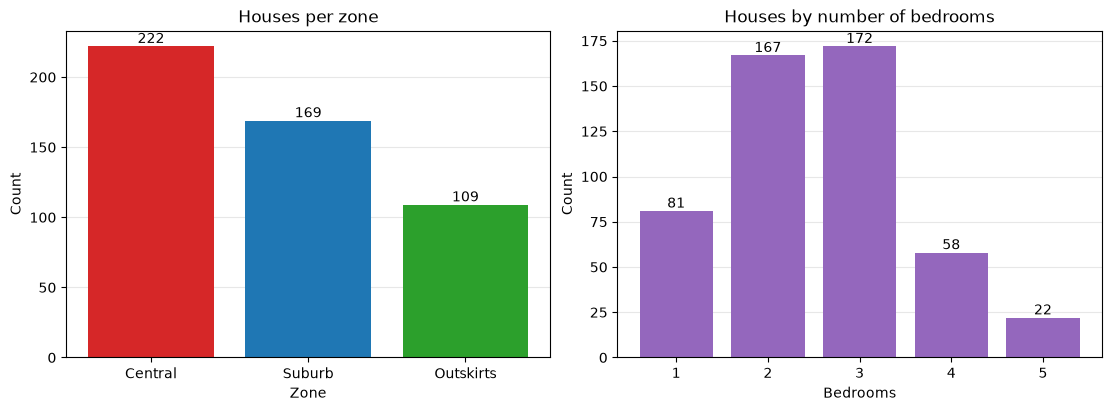

In [16]:
### Categorical variable: counts
zone_counts = df["zone"].value_counts().reindex(["Central", "Suburb", "Outskirts"])
bed_counts  = df["bedrooms"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

bars = axes[0].bar(zone_counts.index, zone_counts.values, color=["tab:red", "tab:blue", "tab:green"])
axes[0].bar_label(bars)                                   # write the count on top of each bar
axes[0].set_title("Houses per zone")
axes[0].set_xlabel("Zone")

bars = axes[1].bar(bed_counts.index.astype(str), bed_counts.values, color="tab:purple")
axes[1].bar_label(bars)
axes[1].set_title("Houses by number of bedrooms")
axes[1].set_xlabel("Bedrooms")

for ax in axes:
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
plt.show()

#  Bivariate Analysis - Two Variables Together


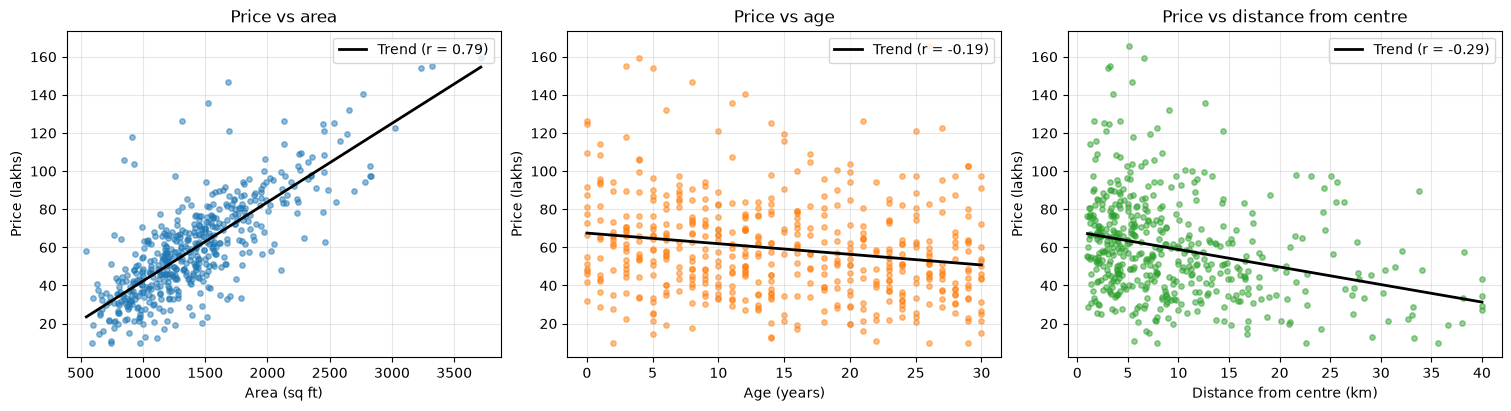

In [17]:
features = ["area_sqft", "age_years", "distance_km"]
names    = ["Area (sq ft)", "Age (years)", "Distance from centre (km)"]
cols     = ["tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, f, nm, c in zip(axes, features, names, cols):
    ax.scatter(df[f], df["price_lakhs"], s=15, alpha=0.5, color=c)
    r = df[f].corr(df["price_lakhs"])
    slope, intercept = np.polyfit(df[f], df["price_lakhs"], 1)          # best-fit straight line
    xs = np.linspace(df[f].min(), df[f].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="black", linewidth=2, label=f"Trend (r = {r:.2f})")
    ax.set_xlabel(nm)
    ax.set_ylabel("Price (lakhs)")
    ax.set_title(f"Price vs {nm.split(' (')[0].lower()}")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

plt.show()

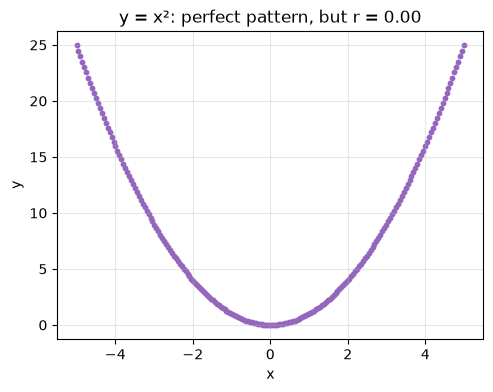

In [18]:
xx = np.linspace(-5, 5, 200)
yy = xx ** 2                                  # perfect relationship, but a curve

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(xx, yy, s=10, color="tab:purple")
ax.set_title(f"y = x²: perfect pattern, but r = {np.corrcoef(xx, yy)[0, 1]:.2f}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(alpha=0.3)
plt.show()

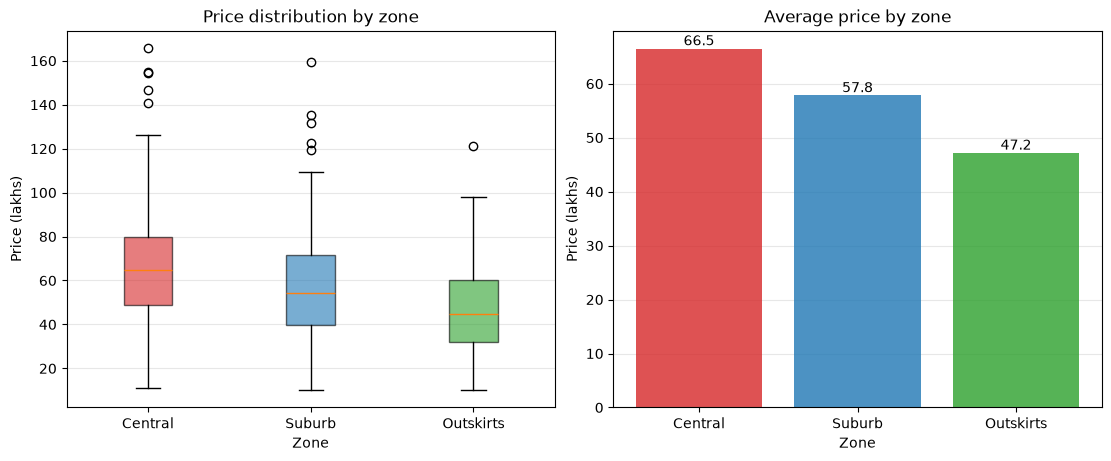

In [19]:
### Numeric vs Categorical: compare groups
order = ["Central", "Suburb", "Outskirts"]
groups = [df.loc[df["zone"] == z, "price_lakhs"] for z in order]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# (a) Box plot per zone: shows spread and outliers in each group
bp = axes[0].boxplot(groups, patch_artist=True)
axes[0].set_xticklabels(order)
for patch, c in zip(bp["boxes"], ["tab:red", "tab:blue", "tab:green"]):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)
axes[0].set_title("Price distribution by zone")

# (b) Bar of group means: one number per group (starts at 0!)
means = df.groupby("zone")["price_lakhs"].mean().reindex(order)
bars = axes[1].bar(order, means.values, color=["tab:red", "tab:blue", "tab:green"], alpha=0.8)
axes[1].bar_label(bars, fmt="%.1f")
axes[1].set_title("Average price by zone")

for ax in axes:
    ax.set_xlabel("Zone")
    ax.set_ylabel("Price (lakhs)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
plt.show()


bedrooms    1   2   3   4  5
zone                        
Central    34  72  83  26  7
Suburb     32  58  51  20  8
Outskirts  15  37  38  12  7


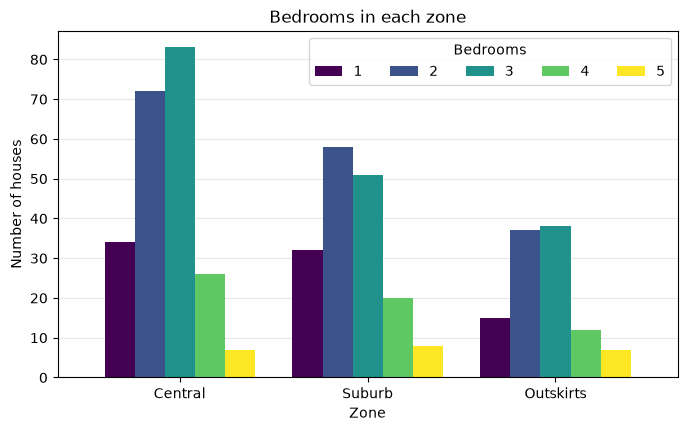

In [20]:
###  Categorical vs Categorical: cross-tab
ct = pd.crosstab(df["zone"], df["bedrooms"]).reindex(order)
print(ct)

fig, ax = plt.subplots(figsize=(8, 4.5))
ct.plot(kind="bar", ax=ax, width=0.8, colormap="viridis", rot=0)
ax.set_title("Bedrooms in each zone")
ax.set_xlabel("Zone")
ax.set_ylabel("Number of houses")
ax.legend(title="Bedrooms", ncol=5, loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

# Multivariate Analysis - Three or More Variables


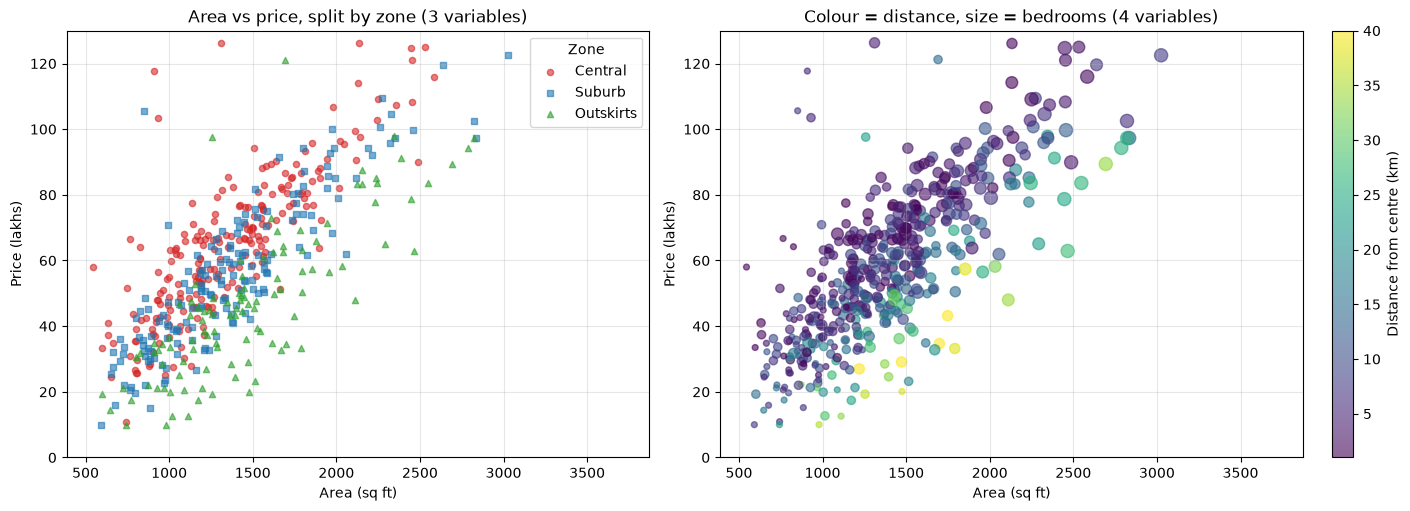

In [21]:
# Adding dimensions to a scatter plot: colour and size
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

# (a) 3 variables: area, price, and zone (categorical -> colour)
for z in order:
    sub = df[df["zone"] == z]
    axes[0].scatter(sub["area_sqft"], sub["price_lakhs"], s=20, alpha=0.6, color=colors[z], marker=markers[z], label=z)
axes[0].set_title("Area vs price, split by zone (3 variables)")
axes[0].legend(title="Zone")

# (b) 4 variables: area, price, distance (colour), bedrooms (size)
sc = axes[1].scatter(df["area_sqft"], df["price_lakhs"],
                     c=df["distance_km"], cmap="viridis", s=df["bedrooms"] * 18, alpha=0.6)
cbar = fig.colorbar(sc, ax=axes[1])
cbar.set_label("Distance from centre (km)")
axes[1].set_title("Colour = distance, size = bedrooms (4 variables)")

for ax in axes:
    ax.set_xlabel("Area (sq ft)")
    ax.set_ylabel("Price (lakhs)")
    ax.set_ylim(0, 130)
    ax.grid(alpha=0.3)
plt.show()

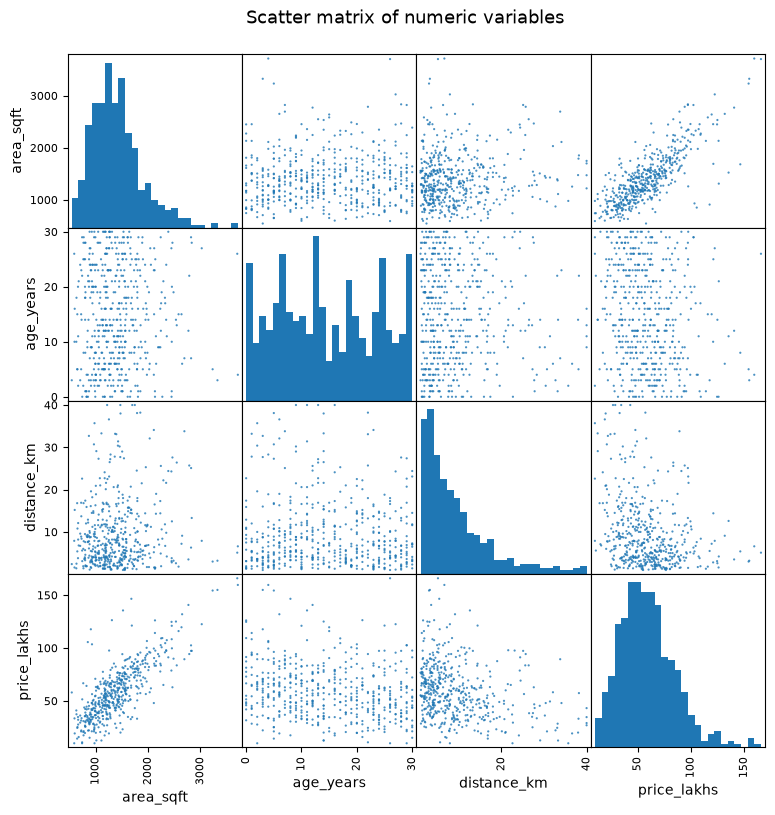

In [22]:
##Scatter matrix (pair plot)
num_cols = ["area_sqft", "age_years", "distance_km", "price_lakhs"]

axs = pd.plotting.scatter_matrix(df[num_cols], figsize=(9, 9), diagonal="hist",
                                 alpha=0.8, s=10, hist_kwds={"bins": 25, "color": "tab:blue"})
plt.suptitle("Scatter matrix of numeric variables", y=0.93, fontsize=13)
plt.show()


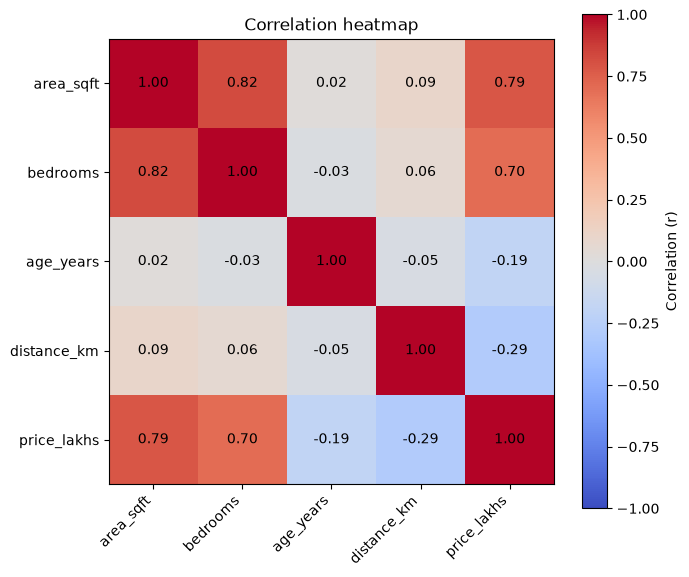

In [23]:
## Correlation heatmap
num_cols = ["area_sqft", "bedrooms", "age_years", "distance_km", "price_lakhs"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)      # fixed range -1..1 so colours are comparable

ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticklabels(num_cols)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10)

fig.colorbar(im, ax=ax, label="Correlation (r)")
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.show()


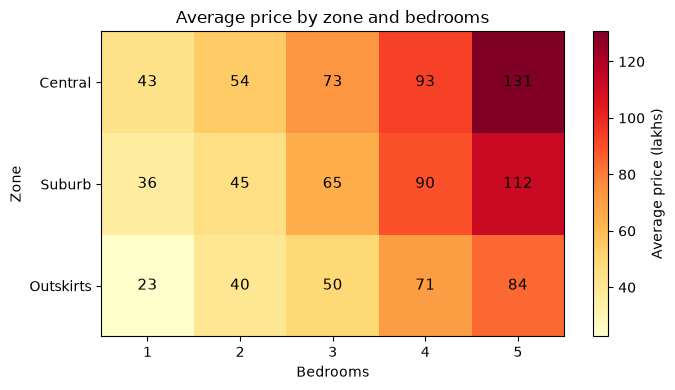

In [24]:
# Pivot-table heatmap: target across two categories
pivot = df.pivot_table(values="price_lakhs", index="zone", columns="bedrooms", aggfunc="mean").reindex(order)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(pivot, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Zone")

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.iloc[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=11)

fig.colorbar(im, ax=ax, label="Average price (lakhs)")
ax.set_title("Average price by zone and bedrooms")
plt.tight_layout()
plt.show()

#  Practice - Apply the Core Concepts


### Beginner - plot formatting
1. Plot `price_lakhs` for the first 50 houses as a line with circle markers, a title, axis labels and a light y-grid.
2. Make a scatter of `age_years` vs `price_lakhs` with `alpha=0.4`, then use `set_ylim` to hide prices above 120.
3. Draw two lines on one Axes (`area_sqft` of the first 50 houses and `price_lakhs` ×10 of the same houses), give each a `label`, and place the legend **outside** the plot.

### Univariate
4. Plot a histogram of `age_years` with 15 bins and mark the mean and median with vertical lines. Is it skewed?
5. Using the IQR rule, count outliers in `area_sqft` and `distance_km`. Which column has more?
6. Draw a bar chart (with counts on the bars) of the number of houses per `bedrooms` value.

### Bivariate
7. Compute the correlation of every numeric column with `price_lakhs` and display it as a **horizontal bar chart** sorted from strongest to weakest.
8. Draw a box plot of `area_sqft` for each zone. Does area differ by zone?
9. Make a grouped bar chart showing the number of houses in each `age_years` band (0-10, 10-20, 20-30) per zone. *Hint: `pd.cut`.*

### Multivariate / ML-focused
10. Create a scatter of `distance_km` vs `price_lakhs` where colour = `age_years` and size = `area_sqft` (scale it down, e.g. `area_sqft / 40`). Add a colour bar.
11. Make a correlation heatmap of `age_years`, `distance_km`, `area_sqft`, `price_lakhs`. Which pair of **features** is the most correlated?
12. Repeat the mini experiment in Section 7 using `["area_sqft", "age_years"]`. Where does its R² fall - between the 1-feature and 4-feature models?
13. Save your best figure as a 300-dpi PNG with `bbox_inches="tight"`.


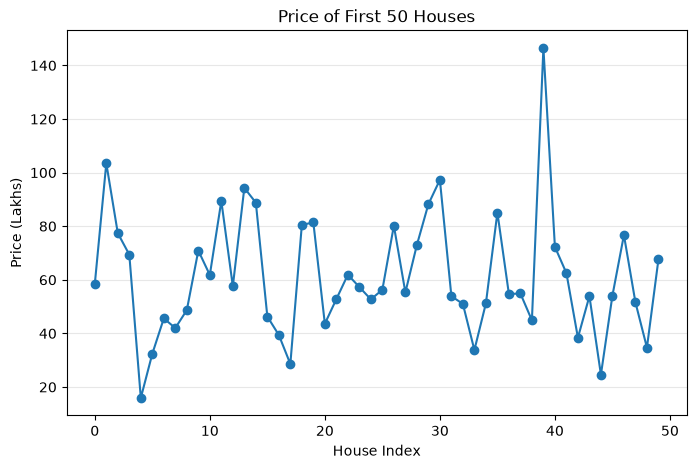

In [25]:
# Task 1
plt.figure(figsize=(8, 5))

plt.plot(df.index[:50], df["price_lakhs"][:50],
         marker="o")

plt.title("Price of First 50 Houses")
plt.xlabel("House Index")
plt.ylabel("Price (Lakhs)")
plt.grid(axis="y", alpha=0.3)

plt.show()

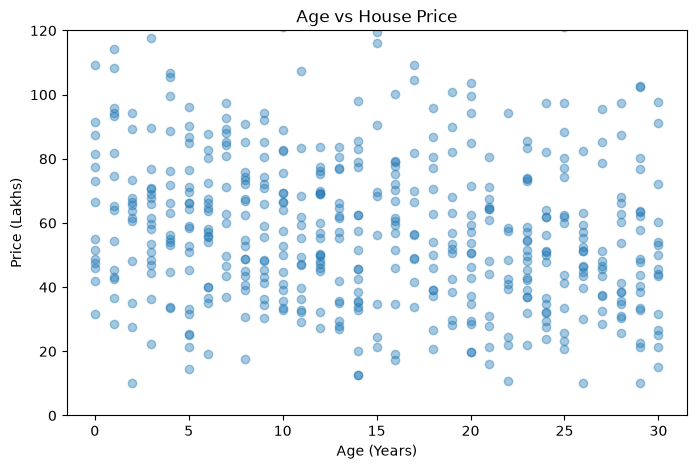

In [26]:
# Task 2
plt.figure(figsize=(8, 5))

plt.scatter(df["age_years"], df["price_lakhs"], alpha=0.4)

plt.title("Age vs House Price")
plt.xlabel("Age (Years)")
plt.ylabel("Price (Lakhs)")

plt.ylim(0, 120)

plt.show()


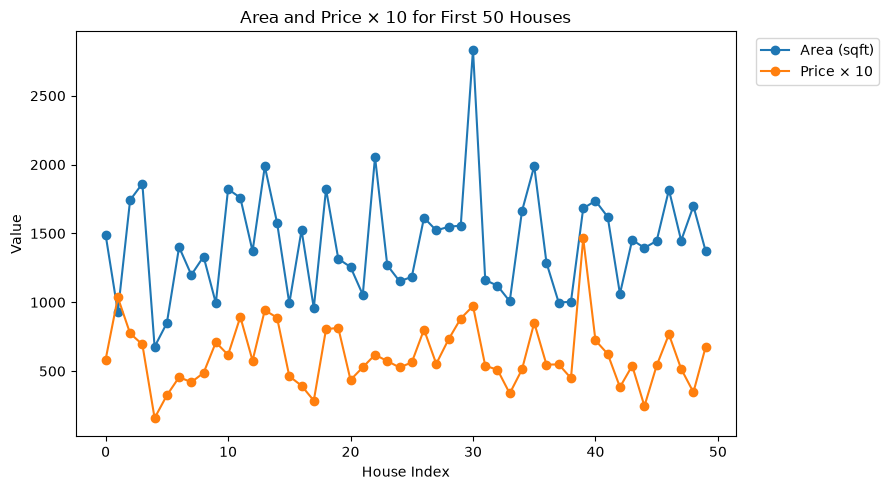

In [27]:
# Task 3
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(df.index[:50], df["area_sqft"][:50],
        marker="o", label="Area (sqft)")

ax.plot(df.index[:50], df["price_lakhs"][:50] * 10,
        marker="o", label="Price × 10")

ax.set_title("Area and Price × 10 for First 50 Houses")
ax.set_xlabel("House Index")
ax.set_ylabel("Value")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

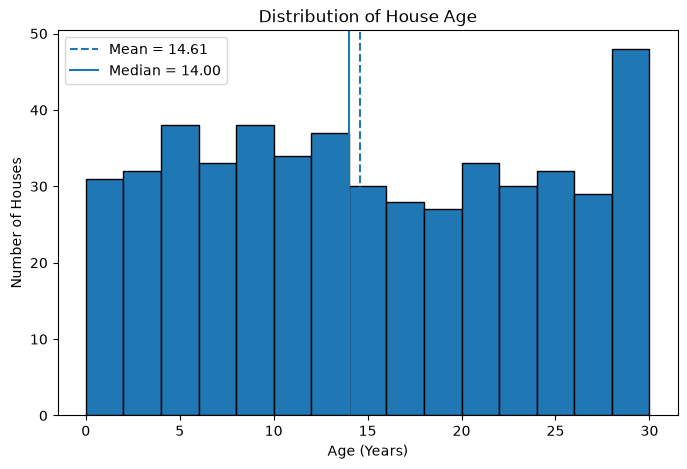

In [28]:
# Task 4
plt.figure(figsize=(8, 5))

plt.hist(df["age_years"], bins=15, edgecolor="black")

mean_age = df["age_years"].mean()
median_age = df["age_years"].median()

plt.axvline(mean_age, linestyle="--", label=f"Mean = {mean_age:.2f}")
plt.axvline(median_age, linestyle="-", label=f"Median = {median_age:.2f}")

plt.title("Distribution of House Age")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Houses")
plt.legend()

plt.show()


In [29]:
# Task 5
def count_outliers(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return ((df[column] < lower) | (df[column] > upper)).sum()

area_outliers = count_outliers("area_sqft")
distance_outliers = count_outliers("distance_km")

print("Area outliers:", area_outliers)
print("Distance outliers:", distance_outliers)

if area_outliers > distance_outliers:
    print("Area_sqft has more outliers.")
elif distance_outliers > area_outliers:
    print("Distance_km has more outliers.")
else:
    print("Both have the same number of outliers.")


Area outliers: 16
Distance outliers: 31
Distance_km has more outliers.


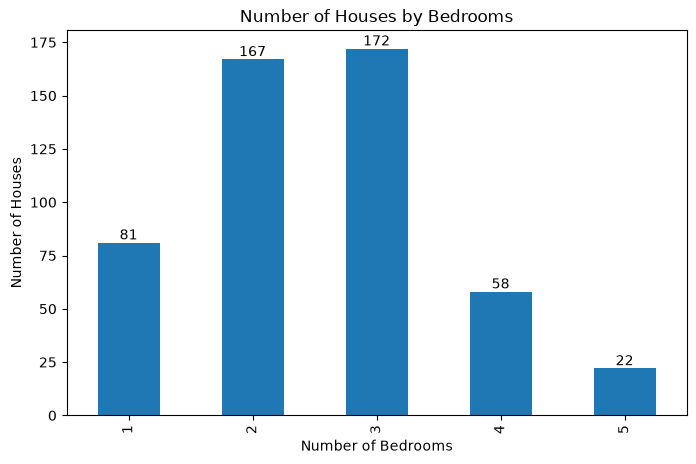

In [30]:
# Task 6
counts = df["bedrooms"].value_counts().sort_index()

ax = counts.plot(kind="bar", figsize=(8, 5))

plt.title("Number of Houses by Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Houses")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

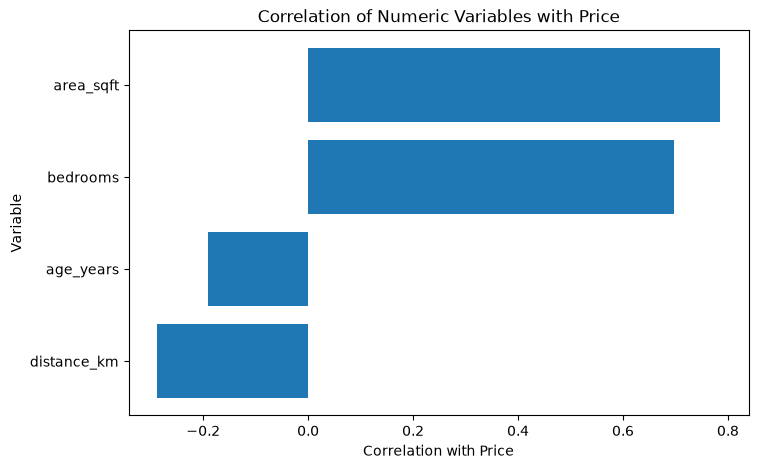

distance_km   -0.288403
age_years     -0.191189
bedrooms       0.698084
area_sqft      0.785705
Name: price_lakhs, dtype: float64


In [31]:
# Task 7
corr = df.select_dtypes(include="number").corr()["price_lakhs"]
corr = corr.drop("price_lakhs").sort_values()

plt.figure(figsize=(8, 5))

plt.barh(corr.index, corr.values)

plt.title("Correlation of Numeric Variables with Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Variable")

plt.show()

print(corr)

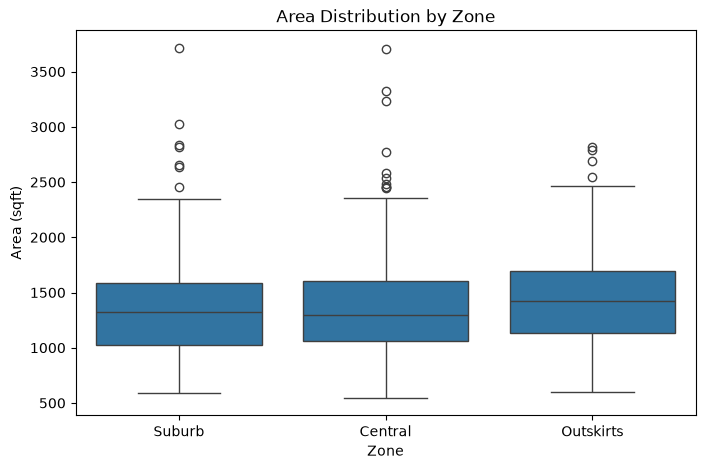

In [32]:
# Task 8
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="zone", y="area_sqft")

plt.title("Area Distribution by Zone")
plt.xlabel("Zone")
plt.ylabel("Area (sqft)")

plt.show()

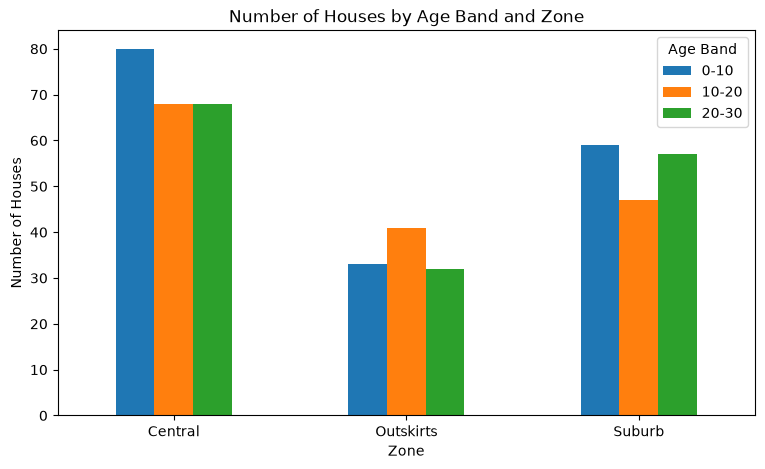

In [33]:
# Task 9
df["age_band"] = pd.cut(
    df["age_years"],
    bins=[0, 10, 20, 30],
    labels=["0-10", "10-20", "20-30"],
    include_lowest=True,
    right=False
)

age_zone = pd.crosstab(df["zone"], df["age_band"])

age_zone.plot(kind="bar", figsize=(9, 5))

plt.title("Number of Houses by Age Band and Zone")
plt.xlabel("Zone")
plt.ylabel("Number of Houses")
plt.xticks(rotation=0)
plt.legend(title="Age Band")

plt.show()

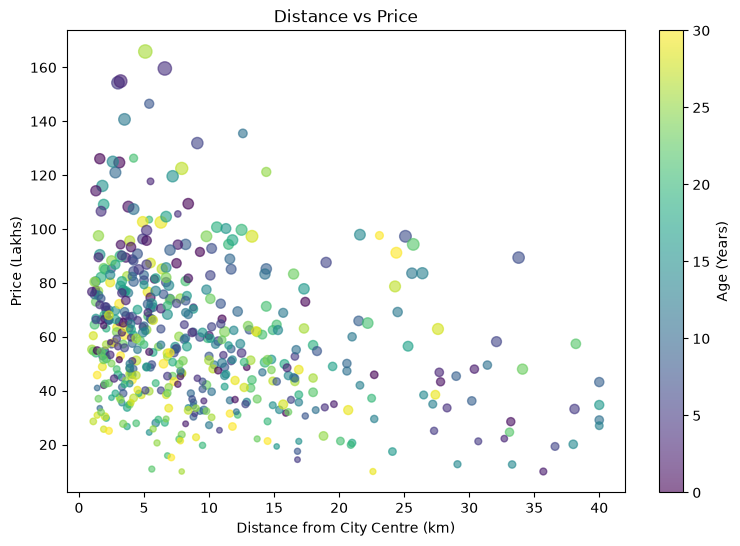

In [34]:
# Task 10
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["distance_km"],
    df["price_lakhs"],
    c=df["age_years"],
    s=df["area_sqft"] / 40,
    alpha=0.6
)

plt.colorbar(scatter, label="Age (Years)")

plt.title("Distance vs Price")
plt.xlabel("Distance from City Centre (km)")
plt.ylabel("Price (Lakhs)")

plt.show()

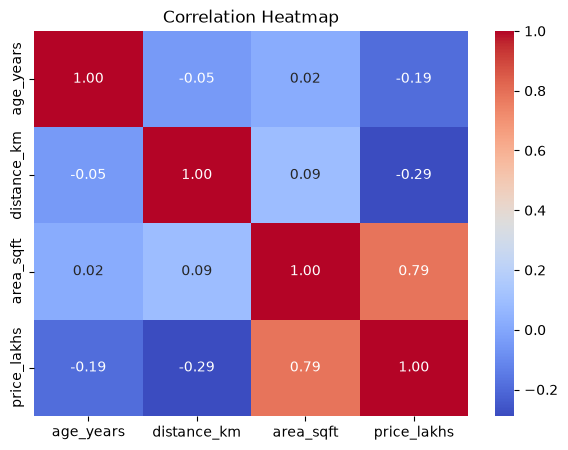

In [35]:
# Task 11
cols = ["age_years", "distance_km", "area_sqft", "price_lakhs"]

corr_matrix = df[cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [36]:
#task 13
plt.savefig(
    "best_figure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>